In [1]:
from MACDFuncs import *
from MACDUtils import *
from MACDcalculators import *
from experiment_test import *
import matplotlib.pyplot as plt
import matplotlib as mpl

plt.style.use("plot_style.txt")
# from os import listdir

alphaRange = [
    -0.9,
    -0.8,
    -0.7,
    -0.5,
    -0.4,
    -0.3,
    -0.2,
    -0.1,
    0,
    0.1,
    0.2,
    0.3,
    0.4,
    0.5,
    0.6,
    0.7,
    0.8,
    0.9,
]
gammaRange = [10, 100, 1000, 10000, 100000, 1000000, 10000000, 100000000]
histogramList, MACDList = return_MACDLists(alphaRange, gammaRange)
# ax.plot(x_list, rule_1_avg_long, label="Rule 1", color = '#2f2d92', linestyle='--', alpha=0.9)
# ax.plot(x_list, rule_2_avg_long, label="Rule 2", color='#e36c14', linestyle='-.', alpha=0.9)
# ax.plot(x_list, macd_avg_long, label="MACD", color = '#666667',  alpha=0.9)

In [2]:
# target_dir = "one_pos"
target_dir = "simulation"

target_dir_save = "one" if target_dir == "one_pos" else "sim"

target_experiment = False
cond = "no"  # "no"
# target_experiment = True; cond = 'sig' # "sig"

market = "stocks"

values_dict = {"Daily": "15", "Hourly": "3", "Minutely": "8"}

# obs_mode = 'observations_MACDCROSS_naked'
obs_mode = "observations_ZEROCROSS_naked"

obs_save = "MACD" if obs_mode == "observations_MACDCROSS_naked" else "ZERO"

strategy_name = obs_mode.split("_")[1]


log_of_returns = load_json_file(
    f"./results/returns/{target_dir}/{target_experiment}/log_of_returns"
)

In [3]:
# len(log_of_returns['stocks']['Hourly']['3']['observations_MACDCROSS_naked']['2021-01-23:2021-04-25'])

In [4]:
time_format = "Hourly"
x_list = sorted(
    list(
        log_of_returns[market][time_format][values_dict[time_format]][obs_mode].keys()
    ),
    key=lambda x: datetime.strptime(x.split(":")[0], "%Y-%m-%d"),
)


rule_1_avg = []
rule_1_avg_long = []

rule_2_avg = []
rule_2_avg_long = []

rule_3_avg = []
rule_3_avg_long = []

macd_avg = []
macd_avg_long = []

all_avg_list = [
    rule_1_avg,
    rule_1_avg_long,
    rule_2_avg,
    rule_2_avg_long,
    rule_3_avg,
    rule_3_avg_long,
    macd_avg,
    macd_avg_long,
]
return_avg_list = [rule_1_avg, rule_2_avg, rule_3_avg, macd_avg]
long_avg_list = [rule_1_avg_long, rule_2_avg_long, rule_3_avg_long, macd_avg_long]

for key in x_list:
    row = log_of_returns[market][time_format][values_dict[time_format]][obs_mode][key]
    # row[0][0], row[0][7], row[0][10] --> rule 1
    # row[1][0], row[1][7], row[1][10] --> rule 2
    # row[2][0], row[2][7], row[2][10] --> rule 3
    # row[3][0], row[3][7], row[3][10] --> MACD

    rule_1_avg.append(row[0][0])
    rule_1_avg_long.append(row[0][7])

    rule_2_avg.append(row[1][0])
    rule_2_avg_long.append(row[1][7])

    rule_3_avg.append(row[2][0])
    rule_3_avg_long.append(row[2][7])

    macd_avg.append(row[3][0])
    macd_avg_long.append(row[3][7])

In [5]:
x_list

['2020-06-27:2020-09-27',
 '2020-07-11:2020-10-11',
 '2020-07-25:2020-10-25',
 '2020-08-08:2020-11-08',
 '2020-08-22:2020-11-22',
 '2020-09-05:2020-12-06',
 '2020-09-19:2020-12-20',
 '2020-10-03:2021-01-03',
 '2020-10-17:2021-01-17',
 '2020-10-31:2021-01-31',
 '2020-11-14:2021-02-14',
 '2020-11-28:2021-02-28',
 '2020-12-12:2021-03-14',
 '2020-12-26:2021-03-28',
 '2021-01-09:2021-04-11',
 '2021-01-23:2021-04-25',
 '2021-02-06:2021-05-09',
 '2021-02-20:2021-05-23',
 '2021-03-06:2021-06-06',
 '2021-03-20:2021-06-20',
 '2021-04-03:2021-07-04',
 '2021-04-17:2021-07-18',
 '2021-05-01:2021-08-01',
 '2021-05-15:2021-08-15',
 '2021-05-29:2021-08-29',
 '2021-06-12:2021-09-12',
 '2021-06-26:2021-09-26',
 '2021-07-10:2021-10-10',
 '2021-07-24:2021-10-24',
 '2021-08-07:2021-11-07',
 '2021-08-21:2021-11-21',
 '2021-09-04:2021-12-05',
 '2021-09-18:2021-12-19',
 '2021-10-02:2022-01-02',
 '2021-10-16:2022-01-16']

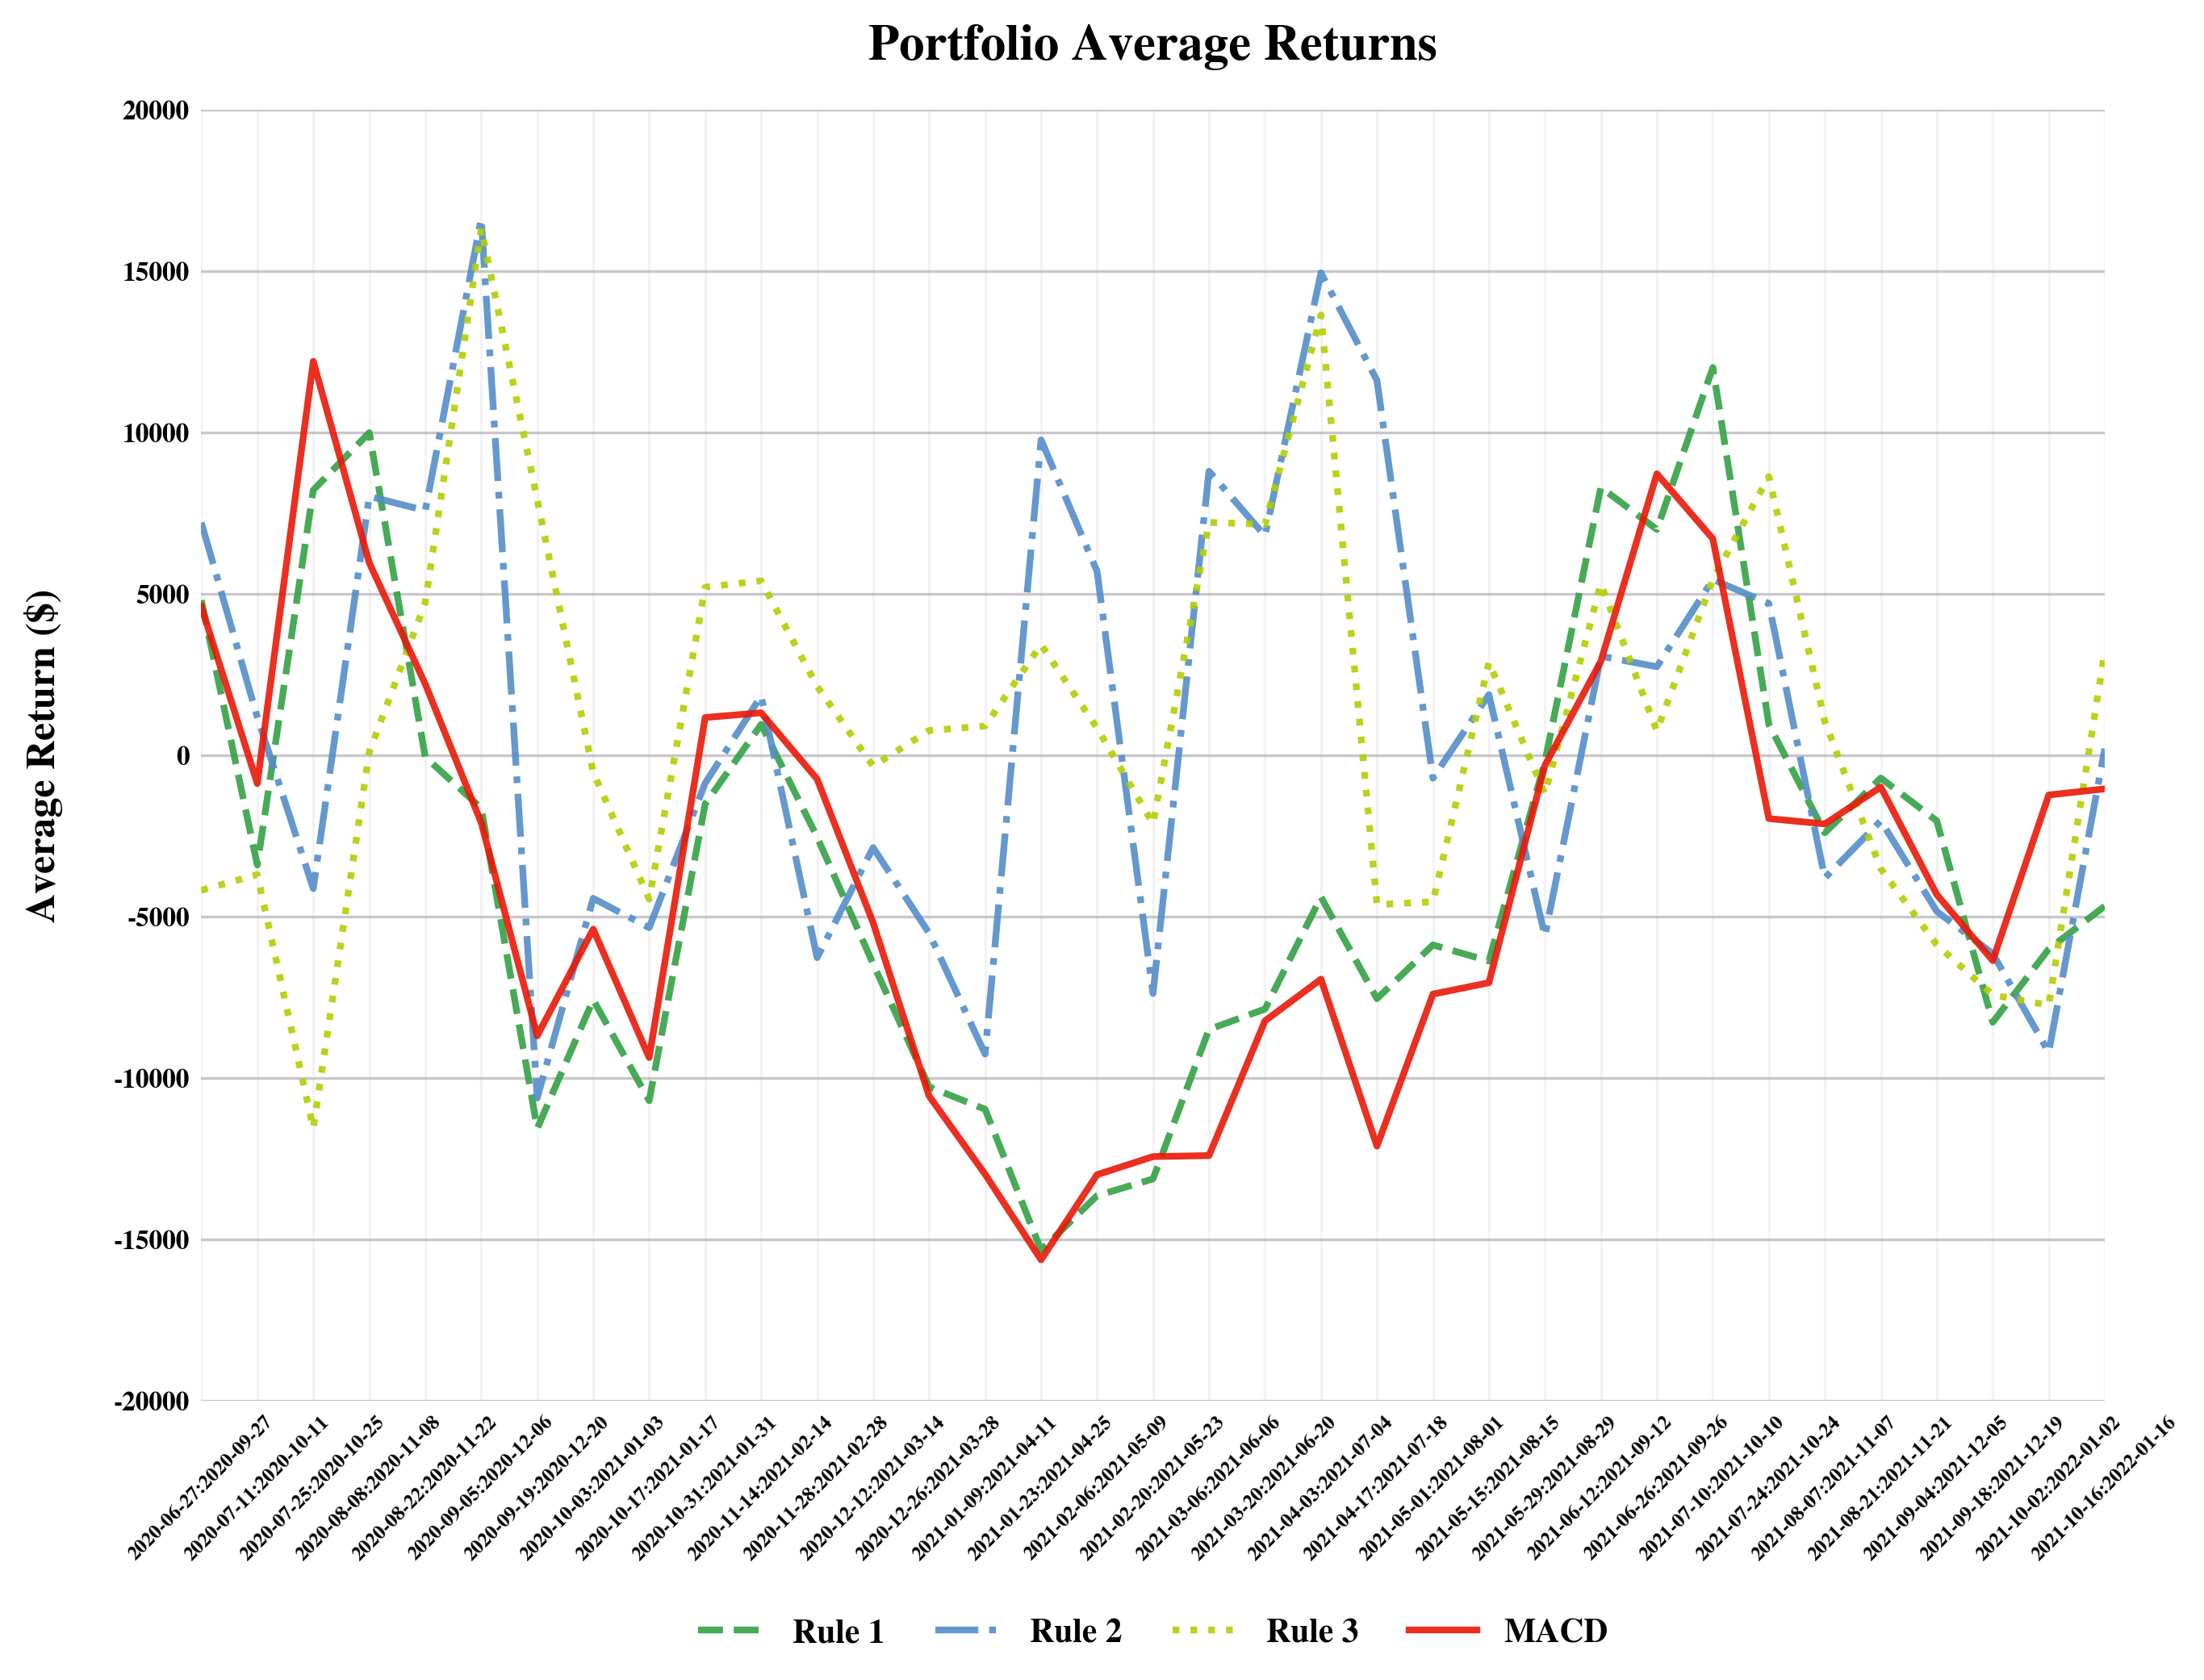

In [6]:
mode = "avg"

fig, ax = plt.subplots()

# avg_y_ticks = list(range(-20000, 17500, 2500))
ax.plot(x_list, rule_1_avg, label="Rule 1", color="#33a144", linestyle="--", alpha=0.9)
ax.plot(x_list, rule_2_avg, label="Rule 2", color="#538dc9", linestyle="-.", alpha=0.9)
ax.plot(x_list, rule_3_avg, label="Rule 3", color="#B3CE00", linestyle=":", alpha=0.9)
ax.plot(x_list, macd_avg, label="MACD", color="#e91807", alpha=0.9)
label_return = "Average Return ($)"


ax.ticklabel_format(axis="y", style="plain")


ax.set_ylabel(label_return, fontweight="bold", fontsize=12, labelpad=15)

ax.xaxis.set_ticks(x_list)
ax.set_xticklabels(x_list, weight="bold", color="black")


avg_y_ticks = list(ax.get_yticks())
if ((avg_y_ticks[1] - avg_y_ticks[0]) % 1) == 0:
    for i in range(len(avg_y_ticks)):
        avg_y_ticks[i] = int(avg_y_ticks[i])
else:
    for i in range(len(avg_y_ticks)):
        avg_y_ticks[i] = round(avg_y_ticks[i], 1)

ax.yaxis.set_ticks(avg_y_ticks)
ax.set_yticklabels(avg_y_ticks, weight="bold", color="black")
ax.set_ylim(avg_y_ticks[0], avg_y_ticks[-1])

plt.rcParams["font.weight"] = "bold"

ax.spines["left"].set_visible(False)
ax.spines["bottom"].set_visible(False)
ax.set_axisbelow(True)
ax.tick_params(axis="both", which="both", length=0)
plt.xticks(rotation=45)

ax.xaxis.grid(alpha=0.15)
ax.yaxis.grid(alpha=0.7)

ax.margins(0)

fig.tight_layout()

fig.set_size_inches(10, 7)
# fig.set_dpi(300)

ax.legend(
    labelcolor="black",
    loc="upper center",
    bbox_to_anchor=(0.5, -0.15),
    ncol=4,
    frameon=False,
)
ax.set_title(
    "Portfolio Average Returns",
    loc="center",
    pad=15,
    size=15,
    fontweight="bold",
    color="black",
)
# plt.savefig(f'./results/plots/{target_dir}/{time_format}/{strategy_name}/{market}_{mode}_{cond}.pdf', bbox_inches='tight')
plt.savefig(
    f"./results/plots/{target_dir}/{time_format}/{strategy_name}/{time_format.lower()}_{target_dir_save}_{obs_save}_{mode}_{cond}.pdf",
    bbox_inches="tight",
)
plt.show()

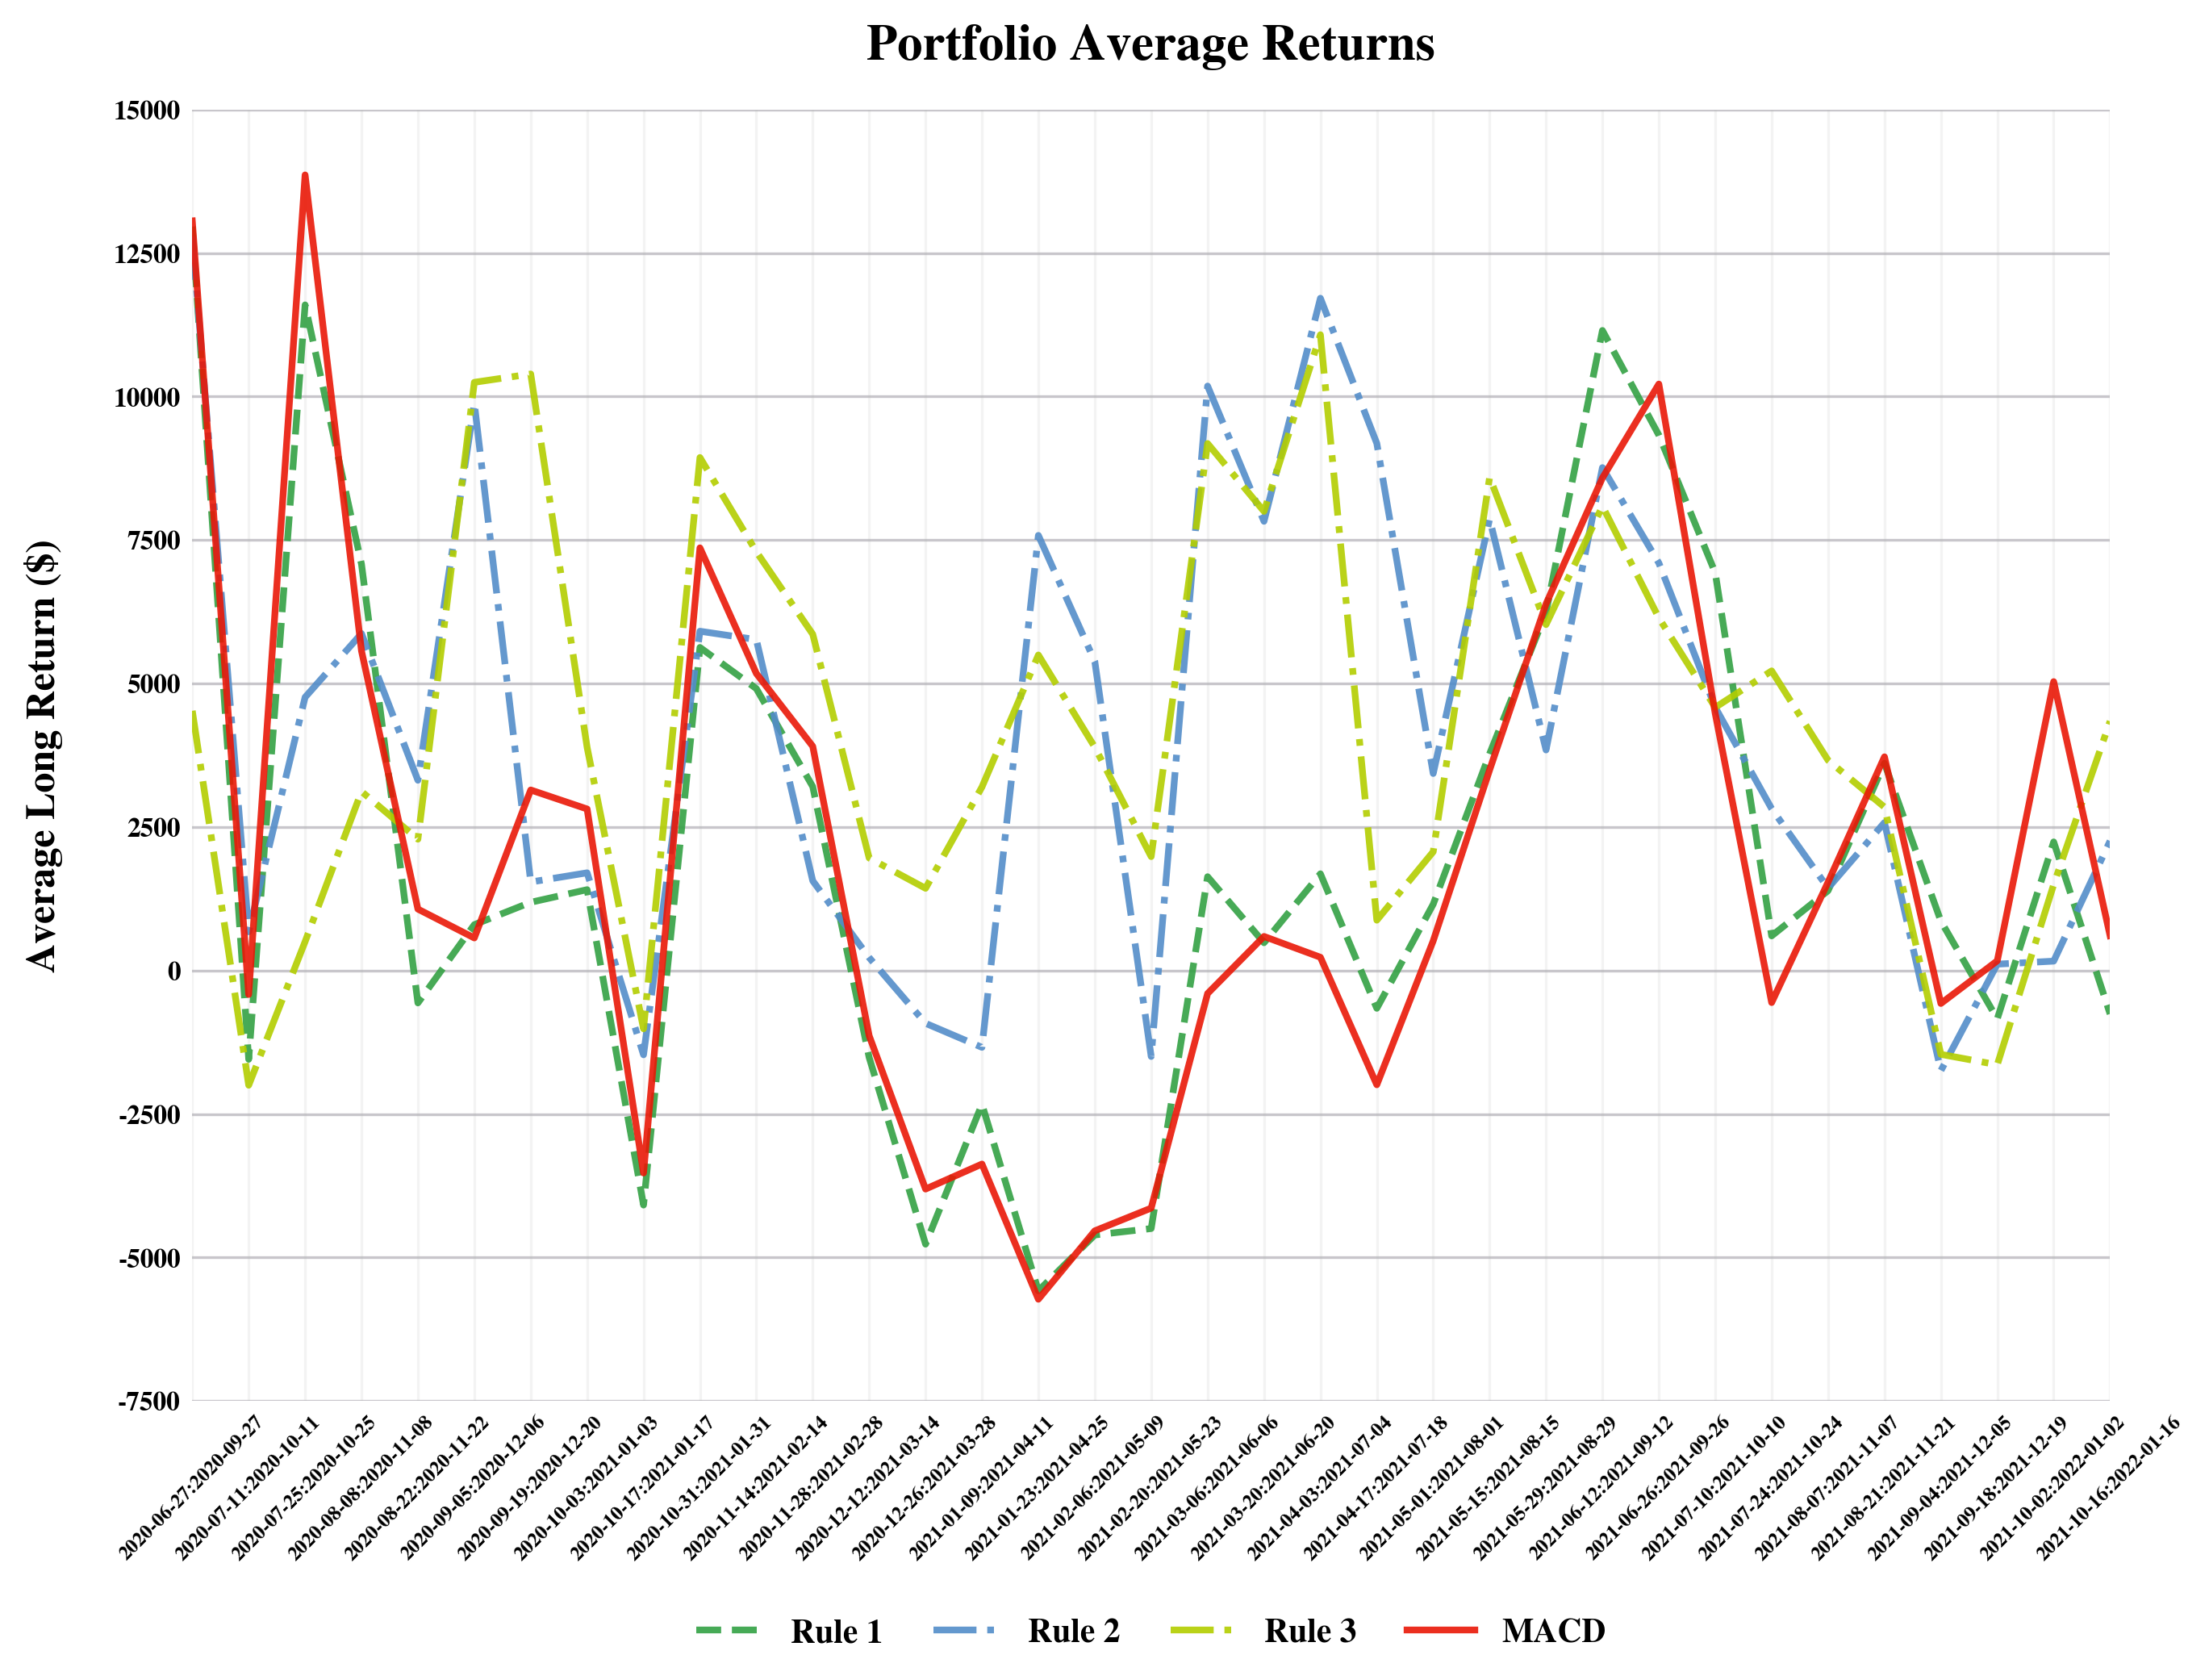

In [7]:
mode = "long"

fig, ax = plt.subplots()


# avg_y_ticks = list(range(-10000, 17500, 2500))
ax.plot(
    x_list, rule_1_avg_long, label="Rule 1", color="#33a144", linestyle="--", alpha=0.9
)
ax.plot(
    x_list, rule_2_avg_long, label="Rule 2", color="#538dc9", linestyle="-.", alpha=0.9
)
ax.plot(
    x_list, rule_3_avg_long, label="Rule 3", color="#B3CE00", linestyle="-.", alpha=0.9
)
ax.plot(x_list, macd_avg_long, label="MACD", color="#e91807", alpha=0.9)
label_return = "Average Long Return ($)"


ax.ticklabel_format(axis="y", style="plain")


ax.set_ylabel(label_return, fontweight="bold", fontsize=12, labelpad=15)

ax.xaxis.set_ticks(x_list)
ax.set_xticklabels(x_list, weight="bold", color="black")


avg_y_ticks = list(ax.get_yticks())
if ((avg_y_ticks[1] - avg_y_ticks[0]) % 1) == 0:
    for i in range(len(avg_y_ticks)):
        avg_y_ticks[i] = int(avg_y_ticks[i])
else:
    for i in range(len(avg_y_ticks)):
        avg_y_ticks[i] = round(avg_y_ticks[i], 1)

ax.yaxis.set_ticks(avg_y_ticks)
ax.set_yticklabels(avg_y_ticks, weight="bold", color="black")
ax.set_ylim(avg_y_ticks[0], avg_y_ticks[-1])

plt.rcParams["font.weight"] = "bold"

ax.spines["left"].set_visible(False)
ax.spines["bottom"].set_visible(False)
ax.set_axisbelow(True)
ax.tick_params(axis="both", which="both", length=0)
plt.xticks(rotation=45)

ax.xaxis.grid(alpha=0.15)
ax.yaxis.grid(alpha=0.7)

ax.margins(0)

fig.tight_layout()

fig.set_size_inches(10, 7)
# fig.set_dpi(300)

ax.legend(
    labelcolor="black",
    loc="upper center",
    bbox_to_anchor=(0.5, -0.15),
    ncol=4,
    frameon=False,
)
ax.set_title(
    "Portfolio Average Returns",
    loc="center",
    pad=15,
    size=15,
    fontweight="bold",
    color="black",
)
plt.savefig(
    f"./results/plots/{target_dir}/{time_format}/{strategy_name}/{time_format.lower()}_{target_dir_save}_{obs_save}_{mode}_{cond}.pdf",
    bbox_inches="tight",
)
plt.show()

In [8]:
time_format = "Minutely"

x_list = sorted(
    list(
        log_of_returns[market][time_format][values_dict[time_format]][obs_mode].keys()
    ),
    key=lambda x: datetime.strptime(x.split(":")[0], "%Y-%m-%d"),
)

rule_1_avg = []
rule_1_avg_long = []

rule_2_avg = []
rule_2_avg_long = []

rule_3_avg = []
rule_3_avg_long = []

macd_avg = []
macd_avg_long = []

all_avg_list = [
    rule_1_avg,
    rule_1_avg_long,
    rule_2_avg,
    rule_2_avg_long,
    rule_3_avg,
    rule_3_avg_long,
    macd_avg,
    macd_avg_long,
]
return_avg_list = [rule_1_avg, rule_2_avg, rule_3_avg, macd_avg]
long_avg_list = [rule_1_avg_long, rule_2_avg_long, rule_3_avg_long, macd_avg_long]

for key in x_list:
    row = log_of_returns[market][time_format][values_dict[time_format]][obs_mode][key]
    # row[0][0], row[0][7], row[0][10] --> rule 1
    # row[1][0], row[1][7], row[1][10] --> rule 2
    # row[2][0], row[2][7], row[2][10] --> rule 3
    # row[3][0], row[3][7], row[3][10] --> MACD

    rule_1_avg.append(row[0][0])
    rule_1_avg_long.append(row[0][7])

    rule_2_avg.append(row[1][0])
    rule_2_avg_long.append(row[1][7])

    rule_3_avg.append(row[2][0])
    rule_3_avg_long.append(row[2][7])

    macd_avg.append(row[3][0])
    macd_avg_long.append(row[3][7])

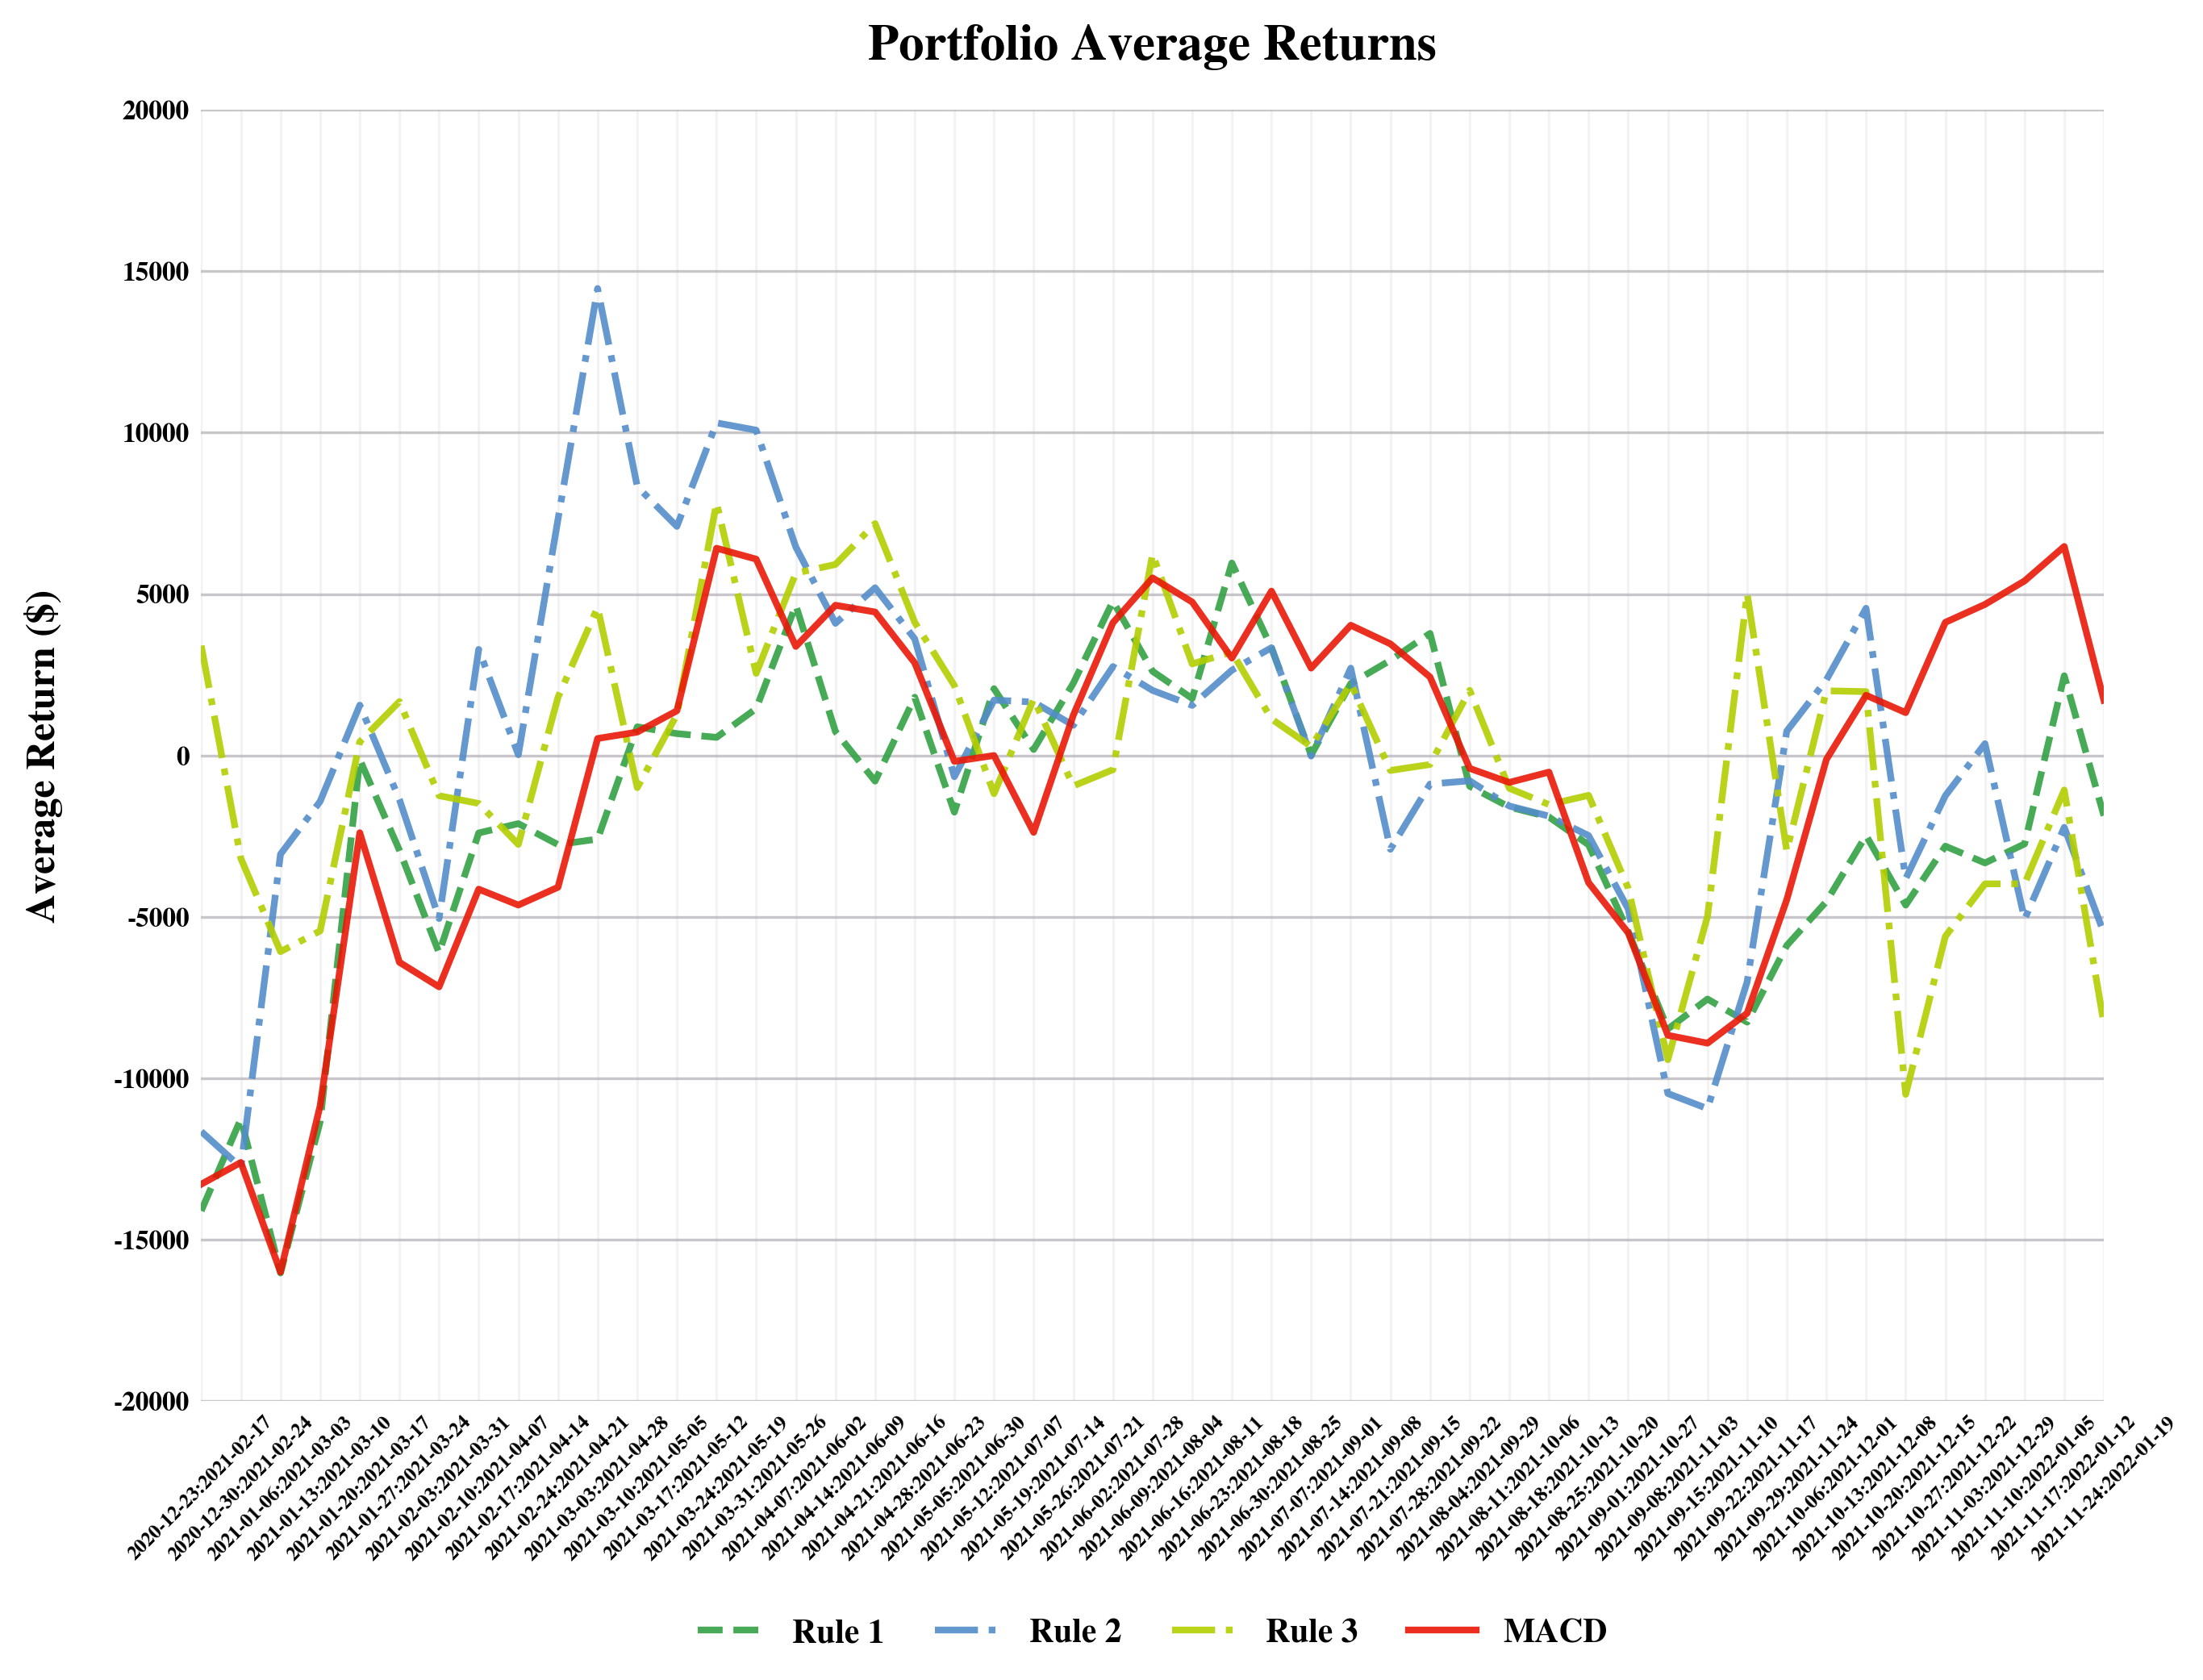

In [9]:
mode = "avg"

fig, ax = plt.subplots()


# avg_y_ticks = list(range(-30000, 12500, 2500))
ax.plot(x_list, rule_1_avg, label="Rule 1", color="#33a144", linestyle="--", alpha=0.9)
ax.plot(x_list, rule_2_avg, label="Rule 2", color="#538dc9", linestyle="-.", alpha=0.9)
ax.plot(x_list, rule_3_avg, label="Rule 3", color="#B3CE00", linestyle="-.", alpha=0.9)
ax.plot(x_list, macd_avg, label="MACD", color="#e91807", alpha=0.9)
label_return = "Average Return ($)"


ax.ticklabel_format(axis="y", style="plain")


ax.set_ylabel(label_return, fontweight="bold", fontsize=12, labelpad=15)

ax.xaxis.set_ticks(x_list)
ax.set_xticklabels(x_list, weight="bold", color="black")


avg_y_ticks = list(ax.get_yticks())
if ((avg_y_ticks[1] - avg_y_ticks[0]) % 1) == 0:
    for i in range(len(avg_y_ticks)):
        avg_y_ticks[i] = int(avg_y_ticks[i])
else:
    for i in range(len(avg_y_ticks)):
        avg_y_ticks[i] = round(avg_y_ticks[i], 1)

ax.yaxis.set_ticks(avg_y_ticks)
ax.set_yticklabels(avg_y_ticks, weight="bold", color="black")
ax.set_ylim(avg_y_ticks[0], avg_y_ticks[-1])

plt.rcParams["font.weight"] = "bold"

ax.spines["left"].set_visible(False)
ax.spines["bottom"].set_visible(False)
ax.set_axisbelow(True)
ax.tick_params(axis="both", which="both", length=0)
plt.xticks(rotation=45)

ax.xaxis.grid(alpha=0.15)
ax.yaxis.grid(alpha=0.7)

ax.margins(0)

fig.tight_layout()

fig.set_size_inches(10, 7)
# fig.set_dpi(300)

ax.legend(
    labelcolor="black",
    loc="upper center",
    bbox_to_anchor=(0.5, -0.15),
    ncol=4,
    frameon=False,
)
ax.set_title(
    "Portfolio Average Returns",
    loc="center",
    pad=15,
    size=15,
    fontweight="bold",
    color="black",
)
plt.savefig(
    f"./results/plots/{target_dir}/{time_format}/{strategy_name}/{time_format.lower()}_{target_dir_save}_{obs_save}_{mode}_{cond}.pdf",
    bbox_inches="tight",
)
plt.show()

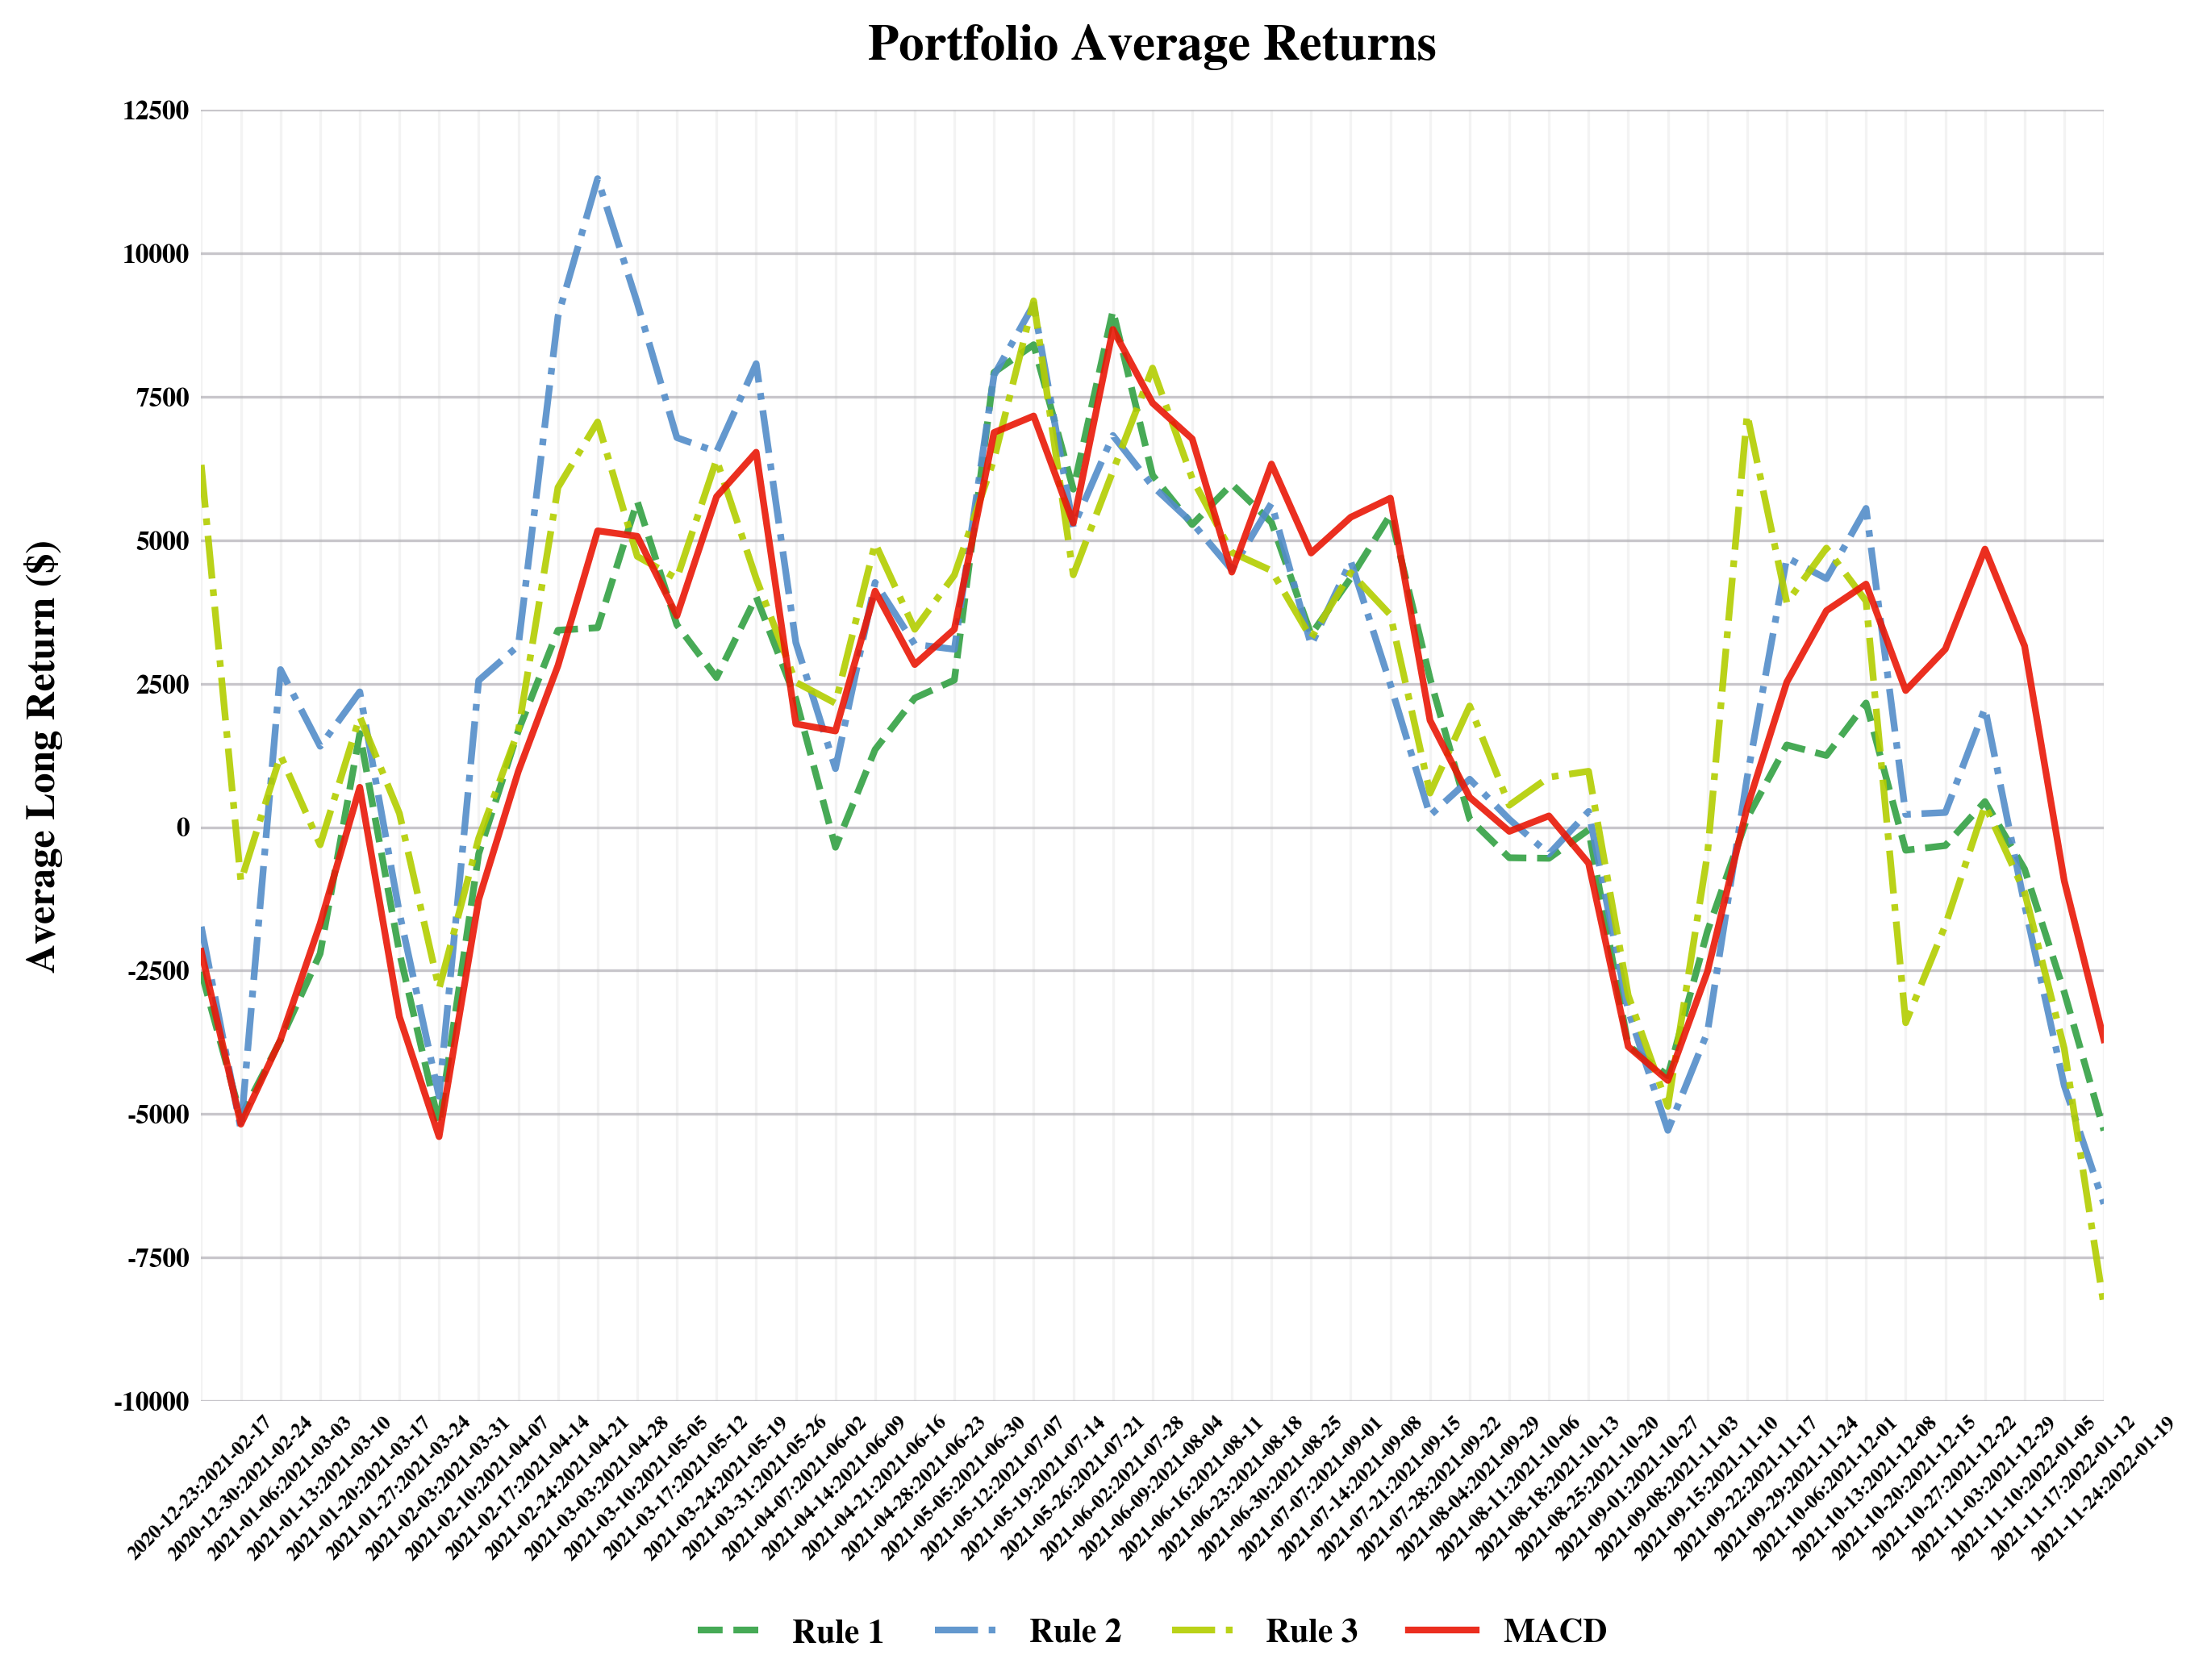

In [10]:
mode = "long"

fig, ax = plt.subplots()


# avg_y_ticks = list(range(-15000, 17500, 2500))
ax.plot(
    x_list, rule_1_avg_long, label="Rule 1", color="#33a144", linestyle="--", alpha=0.9
)
ax.plot(
    x_list, rule_2_avg_long, label="Rule 2", color="#538dc9", linestyle="-.", alpha=0.9
)
ax.plot(
    x_list, rule_3_avg_long, label="Rule 3", color="#B3CE00", linestyle="-.", alpha=0.9
)
ax.plot(x_list, macd_avg_long, label="MACD", color="#e91807", alpha=0.9)
label_return = "Average Long Return ($)"


ax.ticklabel_format(axis="y", style="plain")


ax.set_ylabel(label_return, fontweight="bold", fontsize=12, labelpad=15)

ax.xaxis.set_ticks(x_list)
ax.set_xticklabels(x_list, weight="bold", color="black")


avg_y_ticks = list(ax.get_yticks())
if ((avg_y_ticks[1] - avg_y_ticks[0]) % 1) == 0:
    for i in range(len(avg_y_ticks)):
        avg_y_ticks[i] = int(avg_y_ticks[i])
else:
    for i in range(len(avg_y_ticks)):
        avg_y_ticks[i] = round(avg_y_ticks[i], 1)

ax.yaxis.set_ticks(avg_y_ticks)
ax.set_yticklabels(avg_y_ticks, weight="bold", color="black")
ax.set_ylim(avg_y_ticks[0], avg_y_ticks[-1])

plt.rcParams["font.weight"] = "bold"

ax.spines["left"].set_visible(False)
ax.spines["bottom"].set_visible(False)
ax.set_axisbelow(True)
ax.tick_params(axis="both", which="both", length=0)
plt.xticks(rotation=45)

ax.xaxis.grid(alpha=0.15)
ax.yaxis.grid(alpha=0.7)

ax.margins(0)

fig.tight_layout()

fig.set_size_inches(10, 7)
# fig.set_dpi(300)

ax.legend(
    labelcolor="black",
    loc="upper center",
    bbox_to_anchor=(0.5, -0.15),
    ncol=4,
    frameon=False,
)
ax.set_title(
    "Portfolio Average Returns",
    loc="center",
    pad=15,
    size=15,
    fontweight="bold",
    color="black",
)
plt.savefig(
    f"./results/plots/{target_dir}/{time_format}/{strategy_name}/{time_format.lower()}_{target_dir_save}_{obs_save}_{mode}_{cond}.pdf",
    bbox_inches="tight",
)
plt.show()